# STEP 2: Keypoint Visualization and Data Analysis

In [ ]:
# Path setup: notebooks live in notebooks/, but every path below is relative to the repo root
import os
from pathlib import Path

_here = Path.cwd()
for _cand in (_here, *_here.parents):
    if (_cand / "README.md").exists() and (_cand / "notebooks").is_dir():
        os.chdir(_cand)
        break
print("Working directory:", Path.cwd())

In [1]:
# ==============================
# STEP 2.1: IMPORT VISUALIZATION LIBRARIES
# ==============================
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch
import random
from ultralytics import YOLO
import os

print("🎨 STEP 2: Keypoint Visualization and Data Analysis")
print("=" * 60)

🎨 STEP 2: Keypoint Visualization and Data Analysis


In [2]:
# ==============================
# STEP 2.2: CONFIGURATION FOR VISUALIZATION
# ==============================
VIS_CONFIG = {
    # Model paths (from Step 1 training)
    'side_model_path': 'runs/side_view/yolov8_cow_side_v1/weights/best.pt',
    'back_model_path': 'runs/back_view/yolov8_cow_back_v1/weights/best.pt',
    
    # Data paths
    'side_images': 'data/side_view',
    'back_images': 'data/back_view',
    
    # Visualization settings
    'sample_size': 6,  # Number of sample images to visualize
    'keypoint_radius': 8,
    'skeleton_thickness': 4,
    'text_thickness': 2,
    
    # Colors (BGR format)
    'colors': {
        'keypoints': [(0, 0, 255), (0, 255, 0), (255, 0, 0), (255, 255, 0), 
                     (255, 0, 255), (0, 255, 255), (128, 0, 128), (128, 128, 0),
                     (0, 128, 128), (128, 0, 0)],
        'skeleton': (0, 255, 0),  # Green
        'text': (255, 255, 255)   # White
    },
    
    # Measurement connections with labels
    'side_connections': {
        (0, 9): 'Head Length',
        (2, 4): 'Oblique Body Length', 
        (5, 6): 'Girth Length',
        (1, 7): 'Chest Depth',
        (1, 8): 'Wither Height',
        (3, 4): 'Rump Angle'
    },
    
    'back_connections': {
        (0, 1): 'Rump Width',
        (2, 3): 'Hip Width', 
        (4, 5): 'Tail Length',
        (2, 6): 'Left Hip Height',
        (3, 7): 'Right Hip Height',
        (0, 2): 'Thurl Width (L)',
        (1, 3): 'Thurl Width (R)'
    }
}

print("✅ Visualization configuration loaded")

✅ Visualization configuration loaded


In [3]:
# ==============================
# STEP 2.3: LOAD TRAINED MODELS
# ==============================
def load_trained_models():
    """Load the trained YOLO pose models"""
    print("\n🔧 Loading trained models...")
    
    try:
        side_model = YOLO(VIS_CONFIG['side_model_path'])
        print(f"✅ Side view model loaded: {VIS_CONFIG['side_model_path']}")
    except Exception as e:
        print(f"❌ Error loading side model: {e}")
        side_model = None
    
    try:
        back_model = YOLO(VIS_CONFIG['back_model_path'])
        print(f"✅ Back view model loaded: {VIS_CONFIG['back_model_path']}")
    except Exception as e:
        print(f"❌ Error loading back model: {e}")
        back_model = None
    
    return side_model, back_model

side_model, back_model = load_trained_models()


🔧 Loading trained models...
✅ Side view model loaded: runs/side_view/yolov8_cow_side_v1/weights/best.pt
✅ Back view model loaded: runs/back_view/yolov8_cow_back_v1/weights/best.pt


In [4]:
# ==============================
# STEP 2.4: KEYPOINT VISUALIZATION FUNCTIONS
# ==============================
def draw_keypoints_with_skeleton(image, keypoints, connections, view_type):
    """
    Draw keypoints and skeleton connections on image with measurement labels
    """
    img_vis = image.copy()
    h, w = img_vis.shape[:2]
    
    # Thicker visualization config overrides
    skeleton_thickness = 4   # was thinner, now thicker lines
    keypoint_radius = 8      # bigger keypoints
    text_thickness = 3       # bolder text
    font_scale = 0.9         # slightly larger text
    
    # Draw skeleton connections
    for (i, j), label in connections.items():
        if i < len(keypoints) and j < len(keypoints):
            pt1 = (int(keypoints[i][0]), int(keypoints[i][1]))
            pt2 = (int(keypoints[j][0]), int(keypoints[j][1]))
            
            # Draw thicker line
            cv2.line(img_vis, pt1, pt2, VIS_CONFIG['colors']['skeleton'], 
                     skeleton_thickness)
            
            # Calculate midpoint for label
            mid_x = (pt1[0] + pt2[0]) // 2
            mid_y = (pt1[1] + pt2[1]) // 2
            
            # Draw bolder text label
            cv2.putText(img_vis, label, (mid_x + 10, mid_y), 
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale, 
                        VIS_CONFIG['colors']['text'], text_thickness)
    
    # Draw keypoints with numbers
    for idx, (x, y) in enumerate(keypoints):
        center = (int(x), int(y))
        color = VIS_CONFIG['colors']['keypoints'][idx % len(VIS_CONFIG['colors']['keypoints'])]
        
        # Draw bigger circle
        cv2.circle(img_vis, center, keypoint_radius, color, -1)
        
        # Draw larger keypoint number
        cv2.putText(img_vis, str(idx), (center[0] + 14, center[1]), 
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale, (255, 255, 255), 3)
        cv2.putText(img_vis, str(idx), (center[0] + 14, center[1]), 
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), 1)
    
    return img_vis


def extract_keypoints_from_yolo(results):
    """Extract keypoints from YOLO results"""
    if len(results) == 0 or len(results[0].keypoints.xy) == 0:
        return None
    
    # Get keypoints from first detected object
    keypoints = results[0].keypoints.xy[0].cpu().numpy()
    return keypoints


In [5]:
# ==============================
# STEP 2.5: SAMPLE IMAGE SELECTION
# ==============================
def get_sample_images(view_type, sample_size=6):
    """Get random sample images for visualization"""
    if view_type == 'side':
        image_dir = VIS_CONFIG['side_images']
    else:
        image_dir = VIS_CONFIG['back_images']
    
    # Get all image files
    image_files = [f for f in os.listdir(image_dir) 
                   if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    # Select random samples
    if len(image_files) > sample_size:
        sample_files = random.sample(image_files, sample_size)
    else:
        sample_files = image_files
    
    print(f"📸 Selected {len(sample_files)} {view_type} view images for visualization")
    return [os.path.join(image_dir, f) for f in sample_files]

# Get sample images for both views
side_sample_images = get_sample_images('side', VIS_CONFIG['sample_size'])
back_sample_images = get_sample_images('back', VIS_CONFIG['sample_size'])

📸 Selected 6 side view images for visualization
📸 Selected 6 back view images for visualization



🔄 Processing Side View Samples...

WARNING Image Read Error d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\side_view\91.jpg
❌ Error processing data/side_view\91.jpg: need at least one array to stack

WARNING Image Read Error d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\side_view\73.jpg
❌ Error processing data/side_view\73.jpg: need at least one array to stack

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\side_view\5.png: 480x640 1 animal, 83.5ms
Speed: 4.2ms preprocess, 83.5ms inference, 85.2ms postprocess per image at shape (1, 3, 480, 640)
  Image 3: Detected 10 keypoints

WARNING Image Read Error d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\side_view\76.jpg
❌ Error processing data/side_view\76.jpg: need at least one array to stack

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\side_view\29.png: 480x640 1 animal, 14.1ms
Speed: 3.4ms preprocess, 14.1ms inference, 3.0ms postprocess per image at shape (1, 3, 480, 640)
  Image 5: Detected 10 keypoints

image 1/1 d:\Projects\

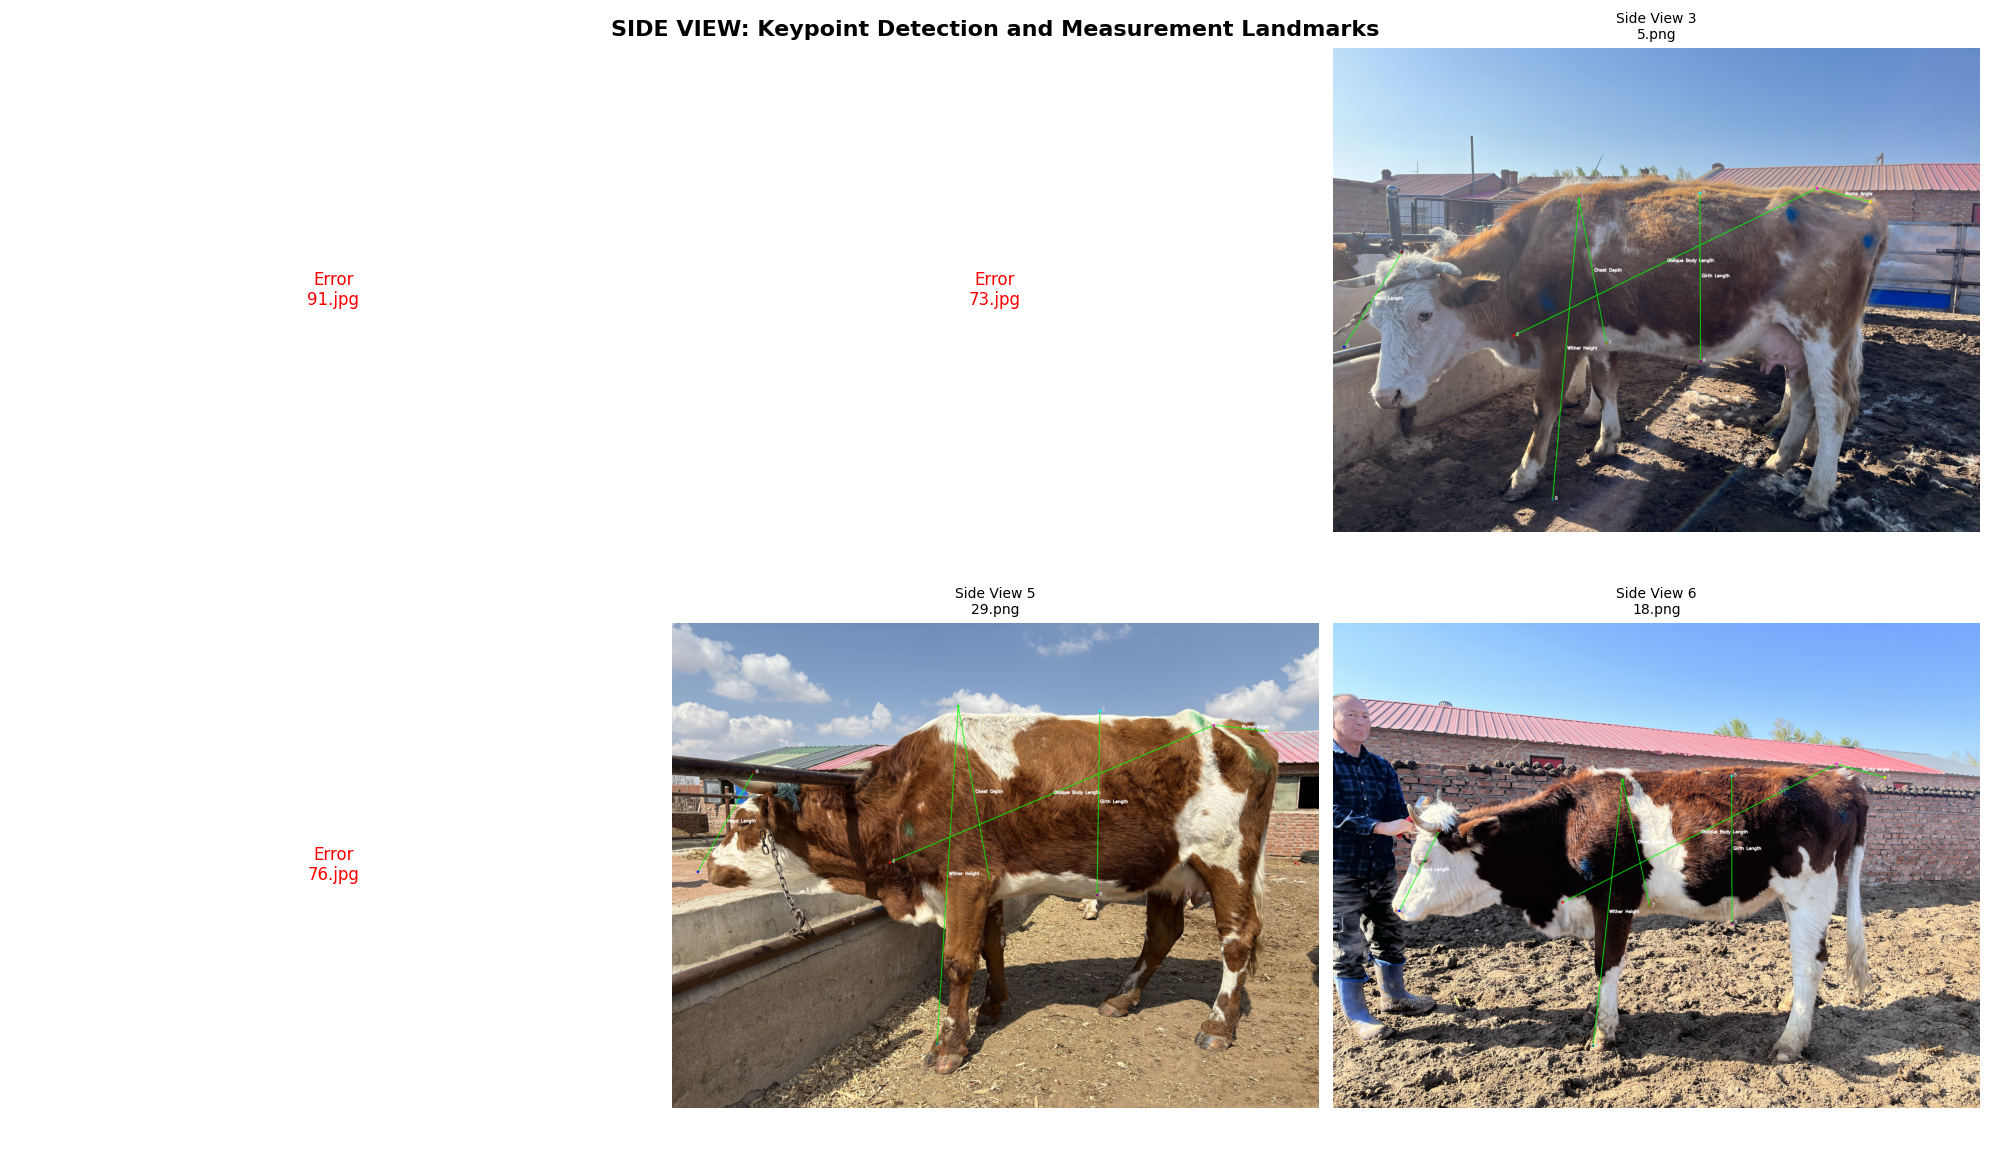

✅ Side view visualization completed and saved


In [6]:
# ==============================
# STEP 2.6: VISUALIZE SIDE VIEW KEYPOINTS
# ==============================
def visualize_side_view_samples():
    """Visualize side view keypoints and measurements"""
    print("\n🔄 Processing Side View Samples...")
    
    if not side_model:
        print("❌ Side model not available, skipping visualization")
        return
    
    # Create figure for side view
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('SIDE VIEW: Keypoint Detection and Measurement Landmarks', 
                fontsize=16, fontweight='bold', y=0.95)
    
    axes = axes.flatten()
    
    for idx, img_path in enumerate(side_sample_images[:6]):
        try:
            # Run inference
            results = side_model.predict(img_path, imgsz=640, conf=0.5)
            
            # Load original image
            img_bgr = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            
            # Extract keypoints
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                # Draw visualization
                vis_img = draw_keypoints_with_skeleton(
                    img_rgb, keypoints, VIS_CONFIG['side_connections'], 'side'
                )
                
                # Plot
                axes[idx].imshow(vis_img)
                axes[idx].set_title(f'Side View {idx+1}\n{os.path.basename(img_path)}', 
                                  fontsize=10)
                axes[idx].axis('off')
                
                # Print keypoint coordinates for debugging
                print(f"  Image {idx+1}: Detected {len(keypoints)} keypoints")
                
            else:
                # Show original image if no keypoints detected
                axes[idx].imshow(img_rgb)
                axes[idx].set_title(f'No Keypoints Detected\n{os.path.basename(img_path)}', 
                                  fontsize=10, color='red')
                axes[idx].axis('off')
                
        except Exception as e:
            print(f"❌ Error processing {img_path}: {e}")
            axes[idx].text(0.5, 0.5, f'Error\n{os.path.basename(img_path)}', 
                         ha='center', va='center', transform=axes[idx].transAxes,
                         fontsize=12, color='red')
            axes[idx].axis('off')
    
    plt.tight_layout()
    plt.savefig('results/figures/side_view_keypoints_visualization.jpg', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("✅ Side view visualization completed and saved")

# Run side view visualization
visualize_side_view_samples()


🔄 Processing Back View Samples...

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\back_view\63.png: 640x480 1 animal, 94.3ms
Speed: 5.9ms preprocess, 94.3ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 480)
  Image 1: Detected 8 keypoints

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\back_view\36.png: 640x480 1 animal, 36.0ms
Speed: 5.7ms preprocess, 36.0ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 480)
  Image 2: Detected 8 keypoints

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\back_view\27.png: 640x480 1 animal, 35.7ms
Speed: 5.2ms preprocess, 35.7ms inference, 2.6ms postprocess per image at shape (1, 3, 640, 480)
  Image 3: Detected 8 keypoints

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\back_view\8.png: 640x480 1 animal, 35.7ms
Speed: 5.0ms preprocess, 35.7ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 480)
  Image 4: Detected 8 keypoints

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\bac

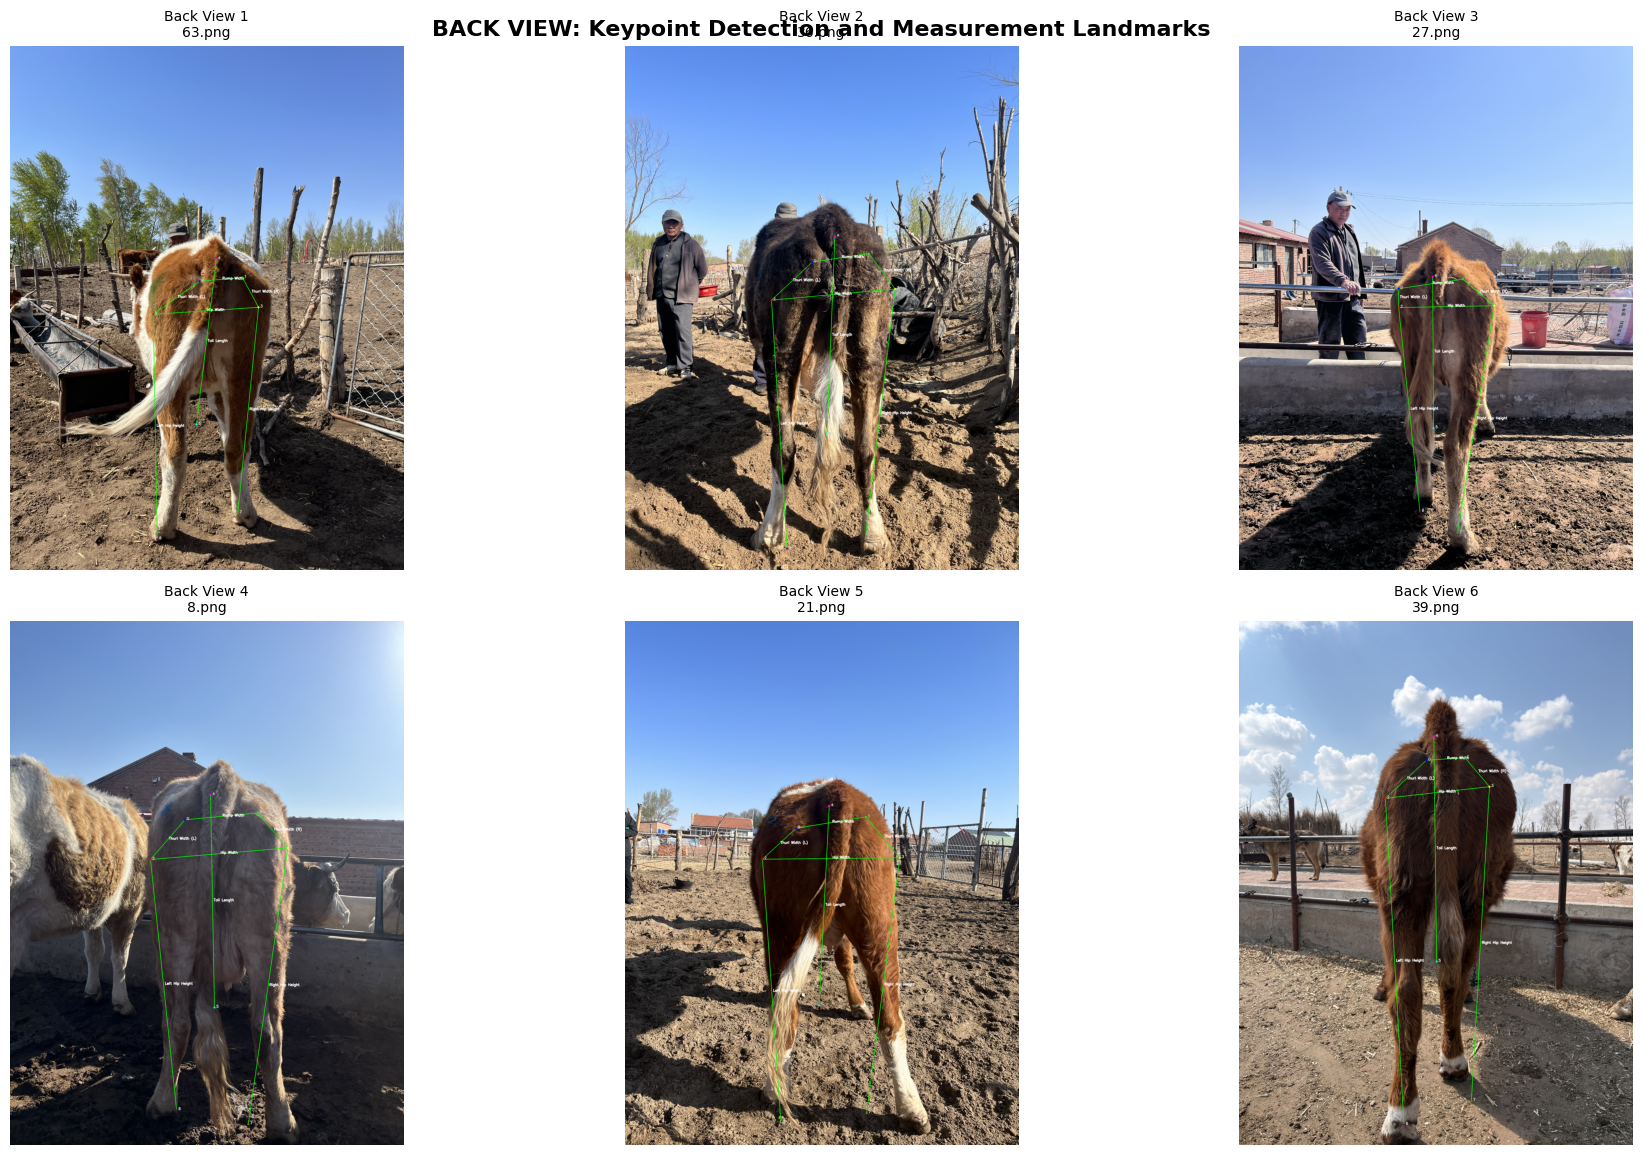

✅ Back view visualization completed and saved


In [7]:
# ==============================
# STEP 2.7: VISUALIZE BACK VIEW KEYPOINTS
# ==============================
def visualize_back_view_samples():
    """Visualize back view keypoints and measurements"""
    print("\n🔄 Processing Back View Samples...")
    
    if not back_model:
        print("❌ Back model not available, skipping visualization")
        return
    
    # Create figure for back view
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('BACK VIEW: Keypoint Detection and Measurement Landmarks', 
                fontsize=16, fontweight='bold', y=0.95)
    
    axes = axes.flatten()
    
    for idx, img_path in enumerate(back_sample_images[:6]):
        try:
            # Run inference
            results = back_model.predict(img_path, imgsz=640, conf=0.5)
            
            # Load original image
            img_bgr = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            
            # Extract keypoints
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                # Draw visualization
                vis_img = draw_keypoints_with_skeleton(
                    img_rgb, keypoints, VIS_CONFIG['back_connections'], 'back'
                )
                
                # Plot
                axes[idx].imshow(vis_img)
                axes[idx].set_title(f'Back View {idx+1}\n{os.path.basename(img_path)}', 
                                  fontsize=10)
                axes[idx].axis('off')
                
                # Print keypoint coordinates for debugging
                print(f"  Image {idx+1}: Detected {len(keypoints)} keypoints")
                
            else:
                # Show original image if no keypoints detected
                axes[idx].imshow(img_rgb)
                axes[idx].set_title(f'No Keypoints Detected\n{os.path.basename(img_path)}', 
                                  fontsize=10, color='red')
                axes[idx].axis('off')
                
        except Exception as e:
            print(f"❌ Error processing {img_path}: {e}")
            axes[idx].text(0.5, 0.5, f'Error\n{os.path.basename(img_path)}', 
                         ha='center', va='center', transform=axes[idx].transAxes,
                         fontsize=12, color='red')
            axes[idx].axis('off')
    
    plt.tight_layout()
    plt.savefig('results/figures/back_view_keypoints_visualization.jpg', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("✅ Back view visualization completed and saved")

# Run back view visualization
visualize_back_view_samples()

In [8]:
# ==============================
# STEP 2.8: KEYPOINT STATISTICS ANALYSIS
# ==============================
def analyze_keypoint_statistics():
    """Analyze keypoint detection statistics"""
    print("\n📊 Analyzing Keypoint Detection Statistics...")
    
    stats = {'side': {}, 'back': {}}
    
    # Analyze side view
    if side_model:
        side_detections = 0
        side_keypoints_count = []
        
        for img_path in side_sample_images:
            results = side_model.predict(img_path, imgsz=640, conf=0.3)
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                side_detections += 1
                side_keypoints_count.append(len(keypoints))
        
        stats['side'] = {
            'detection_rate': side_detections / len(side_sample_images),
            'avg_keypoints': np.mean(side_keypoints_count) if side_keypoints_count else 0,
            'total_samples': len(side_sample_images)
        }
    
    # Analyze back view
    if back_model:
        back_detections = 0
        back_keypoints_count = []
        
        for img_path in back_sample_images:
            results = back_model.predict(img_path, imgsz=640, conf=0.3)
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                back_detections += 1
                back_keypoints_count.append(len(keypoints))
        
        stats['back'] = {
            'detection_rate': back_detections / len(back_sample_images),
            'avg_keypoints': np.mean(back_keypoints_count) if back_keypoints_count else 0,
            'total_samples': len(back_sample_images)
        }
    
    # Print statistics
    print("📈 KEYPOINT DETECTION STATISTICS:")
    print("-" * 50)
    for view_type, data in stats.items():
        if data:
            print(f"{view_type.upper()} VIEW:")
            print(f"  Detection Rate: {data['detection_rate']:.1%}")
            print(f"  Average Keypoints: {data['avg_keypoints']:.1f}")
            print(f"  Samples Analyzed: {data['total_samples']}")
            print()
    
    return stats

# Run statistics analysis
keypoint_stats = analyze_keypoint_statistics()


📊 Analyzing Keypoint Detection Statistics...

WARNING Image Read Error d:\Projects\VETRA\Codes\VETRA v2.0 - N\data\side_view\91.jpg


ValueError: need at least one array to stack

In [ ]:
# ==============================
# STEP 2.9: MEASUREMENT LANDMARK EXPLANATION
# ==============================
def display_measurement_explanations():
    """Display explanation of measurement landmarks"""
    print("\n📐 MEASUREMENT LANDMARK EXPLANATIONS")
    print("=" * 60)
    
    print("\n🔵 SIDE VIEW MEASUREMENTS (10 Keypoints):")
    print("-" * 40)
    for (i, j), measurement in VIS_CONFIG['side_connections'].items():
        print(f"  Keypoints {i}-{j}: {measurement}")
    
    print("\n🔴 BACK VIEW MEASUREMENTS (8 Keypoints):")
    print("-" * 40)
    for (i, j), measurement in VIS_CONFIG['back_connections'].items():
        print(f"  Keypoints {i}-{j}: {measurement}")
    
    print("\n🎯 KEYPOINT NUMBERING:")
    print("Side View: 0-9 (10 points) | Back View: 0-7 (8 points)")
    print("Each number represents a specific anatomical landmark")

# Display explanations
display_measurement_explanations()


📐 MEASUREMENT LANDMARK EXPLANATIONS

🔵 SIDE VIEW MEASUREMENTS (10 Keypoints):
----------------------------------------
  Keypoints 0-9: Head Length
  Keypoints 2-4: Oblique Body Length
  Keypoints 5-6: Girth Length
  Keypoints 1-7: Chest Depth
  Keypoints 1-8: Wither Height
  Keypoints 3-4: Rump Angle

🔴 BACK VIEW MEASUREMENTS (8 Keypoints):
----------------------------------------
  Keypoints 0-1: Rump Width
  Keypoints 2-3: Hip Width
  Keypoints 4-5: Tail Length
  Keypoints 2-6: Left Hip Height
  Keypoints 3-7: Right Hip Height
  Keypoints 0-2: Thurl Width (L)
  Keypoints 1-3: Thurl Width (R)

🎯 KEYPOINT NUMBERING:
Side View: 0-9 (10 points) | Back View: 0-7 (8 points)
Each number represents a specific anatomical landmark



🔄 Creating Comparative Visualization...



image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0\data\side_view\19.png: 480x640 1 animal, 38.2ms
Speed: 4.9ms preprocess, 38.2ms inference, 6.6ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0\data\back_view\60.png: 640x480 1 animal, 35.7ms
Speed: 5.1ms preprocess, 35.7ms inference, 5.9ms postprocess per image at shape (1, 3, 640, 480)


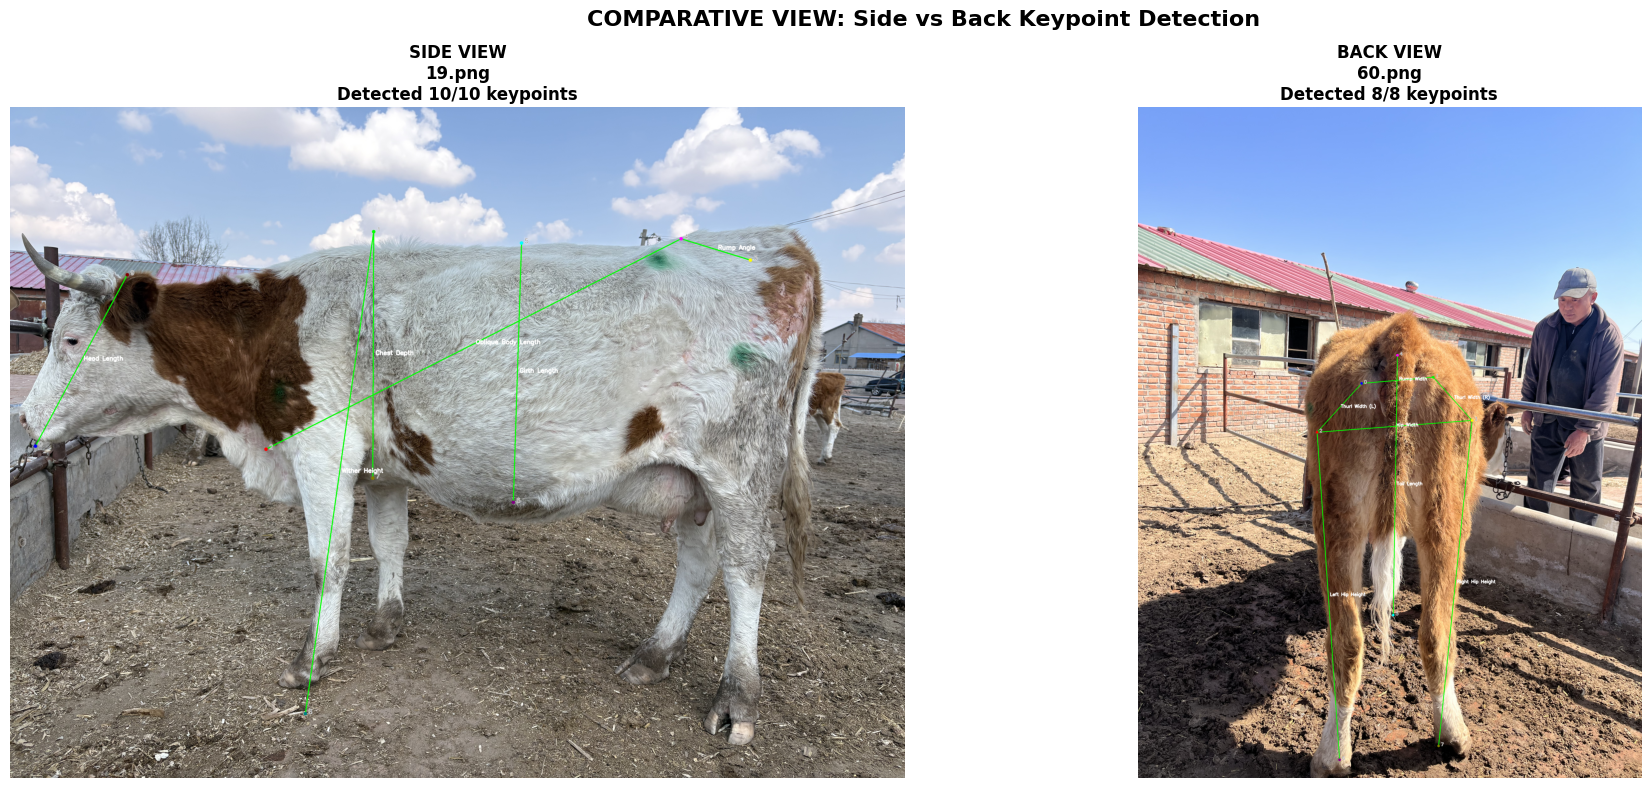

✅ Comparative visualization completed and saved


In [ ]:
# ==============================
# STEP 2.10: CREATE COMPARATIVE VISUALIZATION
# ==============================
def create_comparative_visualization():
    """Create side-by-side comparison of both views"""
    print("\n🔄 Creating Comparative Visualization...")
    
    if not side_model or not back_model:
        print("❌ Models not available for comparison")
        return
    
    # Get one sample from each view
    side_sample = side_sample_images[0] if side_sample_images else None
    back_sample = back_sample_images[0] if back_sample_images else None
    
    if not side_sample or not back_sample:
        print("❌ Not enough samples for comparison")
        return
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    fig.suptitle('COMPARATIVE VIEW: Side vs Back Keypoint Detection', 
                fontsize=16, fontweight='bold')
    
    try:
        # Process side view
        results_side = side_model.predict(side_sample, imgsz=640)
        img_side = cv2.imread(side_sample)
        img_side = cv2.cvtColor(img_side, cv2.COLOR_BGR2RGB)
        keypoints_side = extract_keypoints_from_yolo(results_side)
        
        if keypoints_side is not None:
            vis_side = draw_keypoints_with_skeleton(
                img_side, keypoints_side, VIS_CONFIG['side_connections'], 'side'
            )
            ax1.imshow(vis_side)
            ax1.set_title(f'SIDE VIEW\n{os.path.basename(side_sample)}\n'
                         f'Detected {len(keypoints_side)}/10 keypoints', 
                         fontsize=12, fontweight='bold')
        else:
            ax1.imshow(img_side)
            ax1.set_title(f'SIDE VIEW\nNo Keypoints Detected', 
                         fontsize=12, color='red', fontweight='bold')
        
        ax1.axis('off')
        
        # Process back view
        results_back = back_model.predict(back_sample, imgsz=640)
        img_back = cv2.imread(back_sample)
        img_back = cv2.cvtColor(img_back, cv2.COLOR_BGR2RGB)
        keypoints_back = extract_keypoints_from_yolo(results_back)
        
        if keypoints_back is not None:
            vis_back = draw_keypoints_with_skeleton(
                img_back, keypoints_back, VIS_CONFIG['back_connections'], 'back'
            )
            ax2.imshow(vis_back)
            ax2.set_title(f'BACK VIEW\n{os.path.basename(back_sample)}\n'
                         f'Detected {len(keypoints_back)}/8 keypoints', 
                         fontsize=12, fontweight='bold')
        else:
            ax2.imshow(img_back)
            ax2.set_title(f'BACK VIEW\nNo Keypoints Detected', 
                         fontsize=12, color='red', fontweight='bold')
        
        ax2.axis('off')
        
        plt.tight_layout()
        plt.savefig('results/figures/comparative_view_visualization.jpg', dpi=150, bbox_inches='tight')
        plt.show()
        
        print("✅ Comparative visualization completed and saved")
        
    except Exception as e:
        print(f"❌ Error in comparative visualization: {e}")

# Create comparative visualization
create_comparative_visualization()

In [ ]:
# ==============================
# STEP 2.11: SUMMARY AND QUALITY CHECK
# ==============================
print("\n🎉 STEP 2 COMPLETED SUCCESSFULLY!")
print("=" * 60)
print("📋 WHAT WE ACCOMPLISHED:")
print("   1. ✅ Loaded trained YOLO models for both views")
print("   2. ✅ Visualized keypoints and skeleton connections")
print("   3. ✅ Added measurement labels for each body part")
print("   4. ✅ Analyzed keypoint detection statistics")
print("   5. ✅ Created comparative visualization")
print("   6. ✅ Generated high-quality output images")

print("\n📁 GENERATED FILES:")
print("   - side_view_keypoints_visualization.jpg")
print("   - back_view_keypoints_visualization.jpg") 
print("   - comparative_view_visualization.jpg")

print("\n📊 KEY INSIGHTS:")
if keypoint_stats.get('side'):
    print(f"   Side View: {keypoint_stats['side']['detection_rate']:.1%} detection rate")
if keypoint_stats.get('back'):
    print(f"   Back View: {keypoint_stats['back']['detection_rate']:.1%} detection rate")

print("\n🚀 NEXT STEPS:")
print("   Step 3: Measurement Extraction Pipeline")
print("   Step 4: Scaling Factor Calibration using Excel data")
print("   Step 5: Animal Classification System")

print("\n🔍 QUALITY CHECK:")
print("   Verify that keypoints are placed correctly on anatomical landmarks")
print("   Check that all measurement connections are properly labeled")
print("   Ensure detection rates are acceptable for both views")


🎉 STEP 2 COMPLETED SUCCESSFULLY!
📋 WHAT WE ACCOMPLISHED:
   1. ✅ Loaded trained YOLO models for both views
   2. ✅ Visualized keypoints and skeleton connections
   3. ✅ Added measurement labels for each body part
   4. ✅ Analyzed keypoint detection statistics
   5. ✅ Created comparative visualization
   6. ✅ Generated high-quality output images

📁 GENERATED FILES:
   - side_view_keypoints_visualization.jpg
   - back_view_keypoints_visualization.jpg
   - comparative_view_visualization.jpg

📊 KEY INSIGHTS:
   Side View: 100.0% detection rate
   Back View: 100.0% detection rate

🚀 NEXT STEPS:
   Step 3: Measurement Extraction Pipeline
   Step 4: Scaling Factor Calibration using Excel data
   Step 5: Animal Classification System

🔍 QUALITY CHECK:
   Verify that keypoints are placed correctly on anatomical landmarks
   Check that all measurement connections are properly labeled
   Ensure detection rates are acceptable for both views
